In [2]:
import sys
sys.path.append("..")

from src.data import load_data,time_split,get_xy
from src.evaluate import pr_auc,recall_at_precision

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import  StandardScaler
from sklearn.linear_model import LogisticRegression

In [3]:
df=load_data()
train,valid,test=time_split(df)
X_train,y_train=get_xy(train)
X_valid,y_valid=get_xy(valid)
X_test,y_test=get_xy(test)

for name,y in [("train",y_train),("valid",y_valid),("test",y_test)]:
    print(name,len(y),"rows,",int(y.sum()),"frauds")


train 198608 rows, 366 frauds
valid 42559 rows, 55 frauds
test 42559 rows, 52 frauds


In [4]:
baseline=Pipeline([
    ("scalar",StandardScaler()),
    ("model",LogisticRegression(class_weight="balanced",max_iter=1000)),
])
baseline.fit(X_train,y_train)

scores=baseline.predict_proba(X_valid)[:, 1]
print("PR-AUC(valid): ",round(pr_auc(y_valid,scores),4))
print("Recall @90% precision:",round(recall_at_precision(y_valid,scores),4))
print("Random-guess PR-AUC:", round(y_valid.mean(), 4))


PR-AUC(valid):  0.8372
Recall @90% precision: 0.7636
Random-guess PR-AUC: 0.0013


In [5]:
import pandas as pd
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# how many legit rows per fraud row, used to weight the rare class
spw = (y_train == 0).sum() / (y_train == 1).sum()

models={
    "LogReg (no weights)":Pipeline([("s",StandardScaler()),
                                   ("m",LogisticRegression(max_iter=1000))]),
    "LogReg (balanced)":baseline,
    "LogReg SMOTE":ImbPipeline([("s",StandardScaler()),
                                ("smote",SMOTE(random_state=42)),
                                ("m",LogisticRegression(max_iter=1000))]),
    "XGBoost":  XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=spw, eval_metric="aucpr",
                              n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                               scale_pos_weight=spw, random_state=42,
                               n_jobs=-1, verbose=-1),
}


rows=[]

for name, m in models.items():
    m.fit(X_train,y_train)
    s=m.predict_proba(X_valid)[: ,1]
    rows.append({"model":name,
                 "PR-AUC":pr_auc(y_valid,s),
                 "Recall@90%P": recall_at_precision(y_valid,s)})

results=pd.DataFrame(rows).sort_values("PR-AUC",ascending=False).round(4)
results


,model,PR-AUC,Recall@90%P
3,XGBoost,0.8521,0.7818
2,LogReg SMOTE,0.8408,0.7636
1,LogReg (balanced),0.8372,0.7636
0,LogReg (no weights),0.7789,0.4909
4,LightGBM,0.0734,0.0000


In [6]:
lgbm = models["LightGBM"]

lgbm_scores = lgbm.predict_proba(X_valid)[:, 1]

print("Minimum:", lgbm_scores.min())
print("Maximum:", lgbm_scores.max())
print("Mean:", lgbm_scores.mean())
print("Unique scores:", len(set(lgbm_scores)))

Minimum: 0.0
Maximum: 1.0
Mean: 0.010180978714510278
Unique scores: 1164


In [7]:
variants = {
    "LGBM no weight": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                     random_state=42, n_jobs=-1, verbose=-1),
    "LGBM sqrt weight": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                       min_child_samples=50, scale_pos_weight=spw ** 0.5,
                                       random_state=42, n_jobs=-1, verbose=-1),
}
for name, m in variants.items():
    m.fit(X_train, y_train)
    s = m.predict_proba(X_valid)[:, 1]
    print(name, round(pr_auc(y_valid, s), 4), round(recall_at_precision(y_valid, s), 4))

LGBM no weight 0.2166 0.0
LGBM sqrt weight 0.1566 0.0


In [8]:
lgb = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=8, max_depth=4,
                     min_child_samples=50, subsample=0.8, subsample_freq=1,
                     colsample_bytree=0.8, reg_lambda=5,
                     random_state=42, n_jobs=-1, verbose=-1)
lgb.fit(X_train, y_train)

for name, X, y in [("train", X_train, y_train), ("valid", X_valid, y_valid)]:
    s = lgb.predict_proba(X)[:, 1]
    print(name, round(pr_auc(y, s), 4), round(recall_at_precision(y, s), 4))

train 0.9646 0.9262
valid 0.836 0.7636


Best threshold: 0.54
Cost at best threshold: 278.77
Cost if we flag nothing: 8396.11
Cost if we flag everything: 212520.0
Flagged: 70 | precision: 0.671 | recall: 0.855


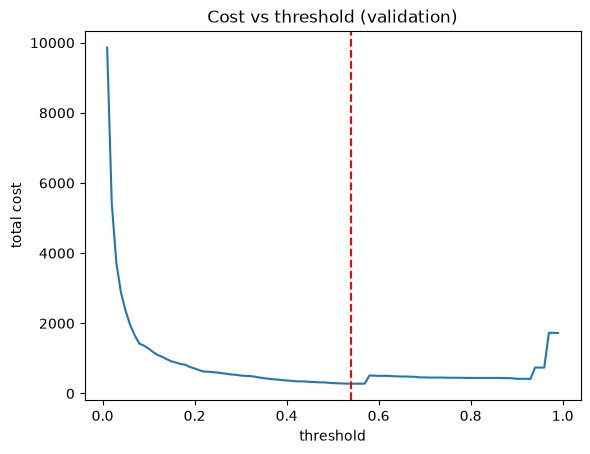

0.3 511.55 | flagged: 118 | recall: 0.873
0.4 371.55 | flagged: 90 | recall: 0.873
0.45 331.55 | flagged: 82 | recall: 0.873
0.5 296.55 | flagged: 75 | recall: 0.873
0.54 278.77 | flagged: 70 | recall: 0.855
0.6 502.8 | flagged: 64 | recall: 0.8


In [9]:
import matplotlib.pyplot as plt
from src.threshold import total_cost, best_threshold
from sklearn.metrics import precision_score, recall_score

xgb = models["XGBoost"]                       # already trained on train data
s_valid = xgb.predict_proba(X_valid)[:, 1]

t, cost, grid, costs = best_threshold(y_valid, s_valid, X_valid["Amount"])
flag_nothing = X_valid.loc[y_valid == 1, "Amount"].sum()
flag_all = 5.0 * (y_valid == 0).sum()

print("Best threshold:", round(t, 2))
print("Cost at best threshold:", round(cost, 2))
print("Cost if we flag nothing:", round(flag_nothing, 2))
print("Cost if we flag everything:", round(flag_all, 2))

pred = s_valid >= t
print("Flagged:", int(pred.sum()),
      "| precision:", round(precision_score(y_valid, pred), 3),
      "| recall:", round(recall_score(y_valid, pred), 3))

plt.plot(grid, costs)
plt.axvline(t, color="red", linestyle="--")
plt.xlabel("threshold"); plt.ylabel("total cost"); plt.title("Cost vs threshold (validation)")
plt.show()

for th in [0.30, 0.40, 0.45, 0.50, 0.54, 0.60]:
    pred = s_valid >= th
    print(th, round(total_cost(y_valid, s_valid, X_valid["Amount"], th), 2),
          "| flagged:", int(pred.sum()),
          "| recall:", round(recall_score(y_valid, pred), 3))

In [10]:
import json, joblib

THRESHOLD = 0.5
joblib.dump(xgb, "../models/model.pkl")
with open("../models/threshold.json", "w") as f:
    json.dump({"threshold": THRESHOLD, "fp_cost": 5.0,
               "features": list(X_train.columns)}, f)

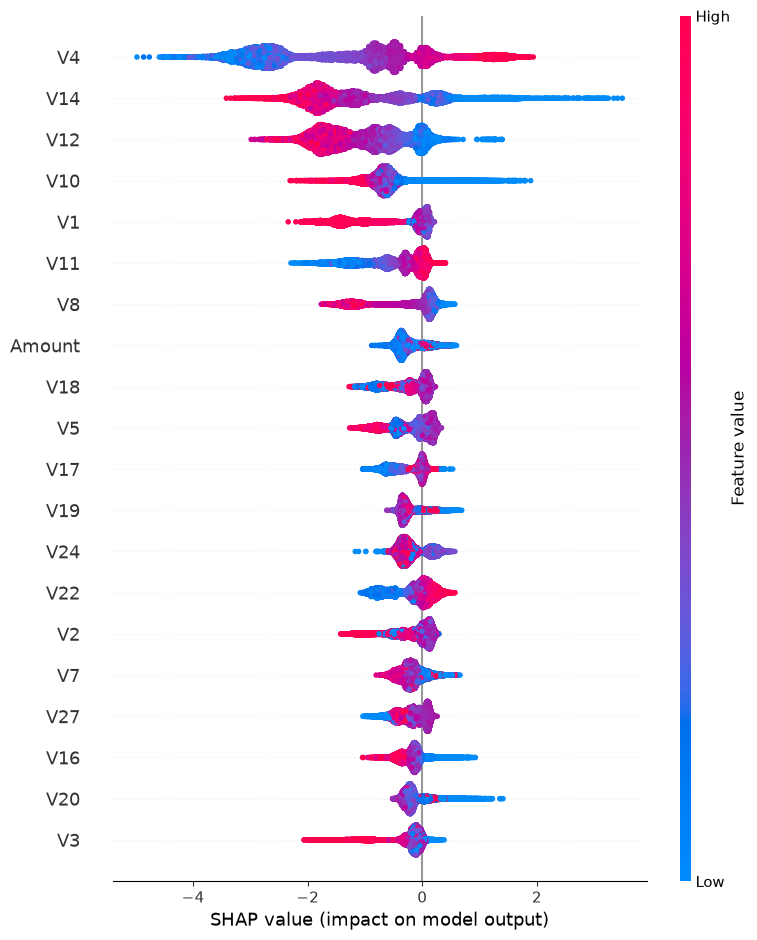

Score: 1.0
V14    3.163741
V10    1.653563
V12    1.281421
V16    0.818664
V4     0.782124
dtype: float32


In [11]:
import shap
import numpy as np
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(X_valid)

shap.summary_plot(sv, X_valid, show=False)
plt.savefig("../reports/figures/shap_summary.png", bbox_inches="tight")
plt.show()

i = int(np.argmax(s_valid))                       # the riskiest transaction in validation
top = pd.Series(sv[i], index=X_valid.columns).sort_values(key=abs, ascending=False).head(5)
print("Score:", round(float(s_valid[i]), 3))
print(top)

Each dot is one transaction. Right of zero pushes the score toward fraud, left pushes toward legit. Red means a high feature value and blue a low one.
V4 and V11: high values (red) push toward fraud.
V14, V12 and V10: low values (blue) push toward fraud. High values push strongly toward legit.
The top drivers are V4, V14, V12, V10, V1, V11, V8, then Amount. A handful of features carry most of the signal, which matches the correlations from your EDA.


In [12]:
sample = pd.concat([
    valid[valid["Class"] == 1],
    valid[valid["Class"] == 0].sample(300, random_state=42),
]).drop(columns=["Time"]).sample(frac=1, random_state=42)
sample.to_csv("../data/sample.csv", index=False)
print(sample.shape)

(355, 30)


In [13]:
s_test = xgb.predict_proba(X_test)[:, 1]
pred = s_test >= THRESHOLD

print("PR-AUC (test):", round(pr_auc(y_test, s_test), 4))
print("Recall @ 90% precision:", round(recall_at_precision(y_test, s_test), 4))
print("Flagged:", int(pred.sum()),
      "| precision:", round(precision_score(y_test, pred), 3),
      "| recall:", round(recall_score(y_test, pred), 3))
print("Cost at threshold:", round(total_cost(y_test, s_test, X_test["Amount"], THRESHOLD), 2))
print("Cost if flag nothing:", round(X_test.loc[y_test == 1, "Amount"].sum(), 2))

PR-AUC (test): 0.7571
Recall @ 90% precision: 0.75
Flagged: 66 | precision: 0.591 | recall: 0.75
Cost at threshold: 2507.4
Cost if flag nothing: 6168.88


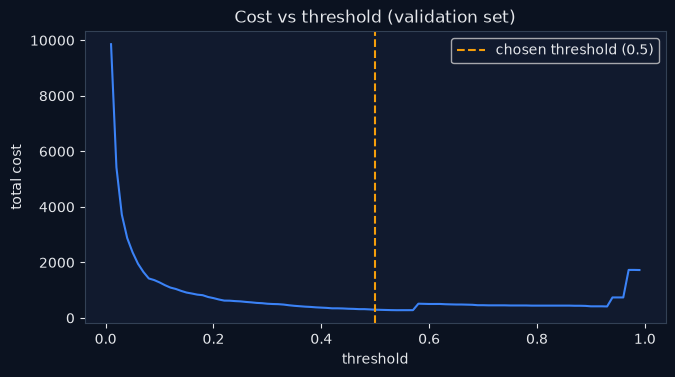

In [14]:
from pathlib import Path
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

DARK = {"figure.facecolor": "#0B1220", "axes.facecolor": "#111A2E",
        "savefig.facecolor": "#0B1220", "text.color": "#E5E7EB",
        "axes.labelcolor": "#E5E7EB", "xtick.color": "#E5E7EB",
        "ytick.color": "#E5E7EB", "axes.edgecolor": "#334155",
        "axes.titlecolor": "#E5E7EB", "axes.grid": False}

with plt.rc_context(DARK):
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.plot(grid, costs, color="#3B82F6")
    ax.axvline(0.5, color="#F59E0B", linestyle="--", label="chosen threshold (0.5)")
    ax.set_xlabel("threshold")
    ax.set_ylabel("total cost")
    ax.set_title("Cost vs threshold (validation set)")
    ax.legend()
    fig.savefig(FIG / "cost_curve.png", bbox_inches="tight", dpi=150)
    plt.show()

In [15]:
s_test = xgb.predict_proba(X_test)[:, 1]
pred = s_test >= THRESHOLD

tp = int(((pred == 1) & (y_test == 1)).sum())
fp = int(((pred == 1) & (y_test == 0)).sum())
fn = int(((pred == 0) & (y_test == 1)).sum())
tn = int(((pred == 0) & (y_test == 0)).sum())

print("PR-AUC:", round(pr_auc(y_test, s_test), 4))
print("Recall @ 90% precision:", round(recall_at_precision(y_test, s_test), 4))
print("Flagged:", int(pred.sum()))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall:", round(recall_score(y_test, pred), 3))
print("Cost at threshold:", round(total_cost(y_test, s_test, X_test["Amount"], THRESHOLD), 2))
print("Cost if flag nothing:", round(X_test.loc[y_test == 1, "Amount"].sum(), 2))
print("tp, fp, fn, tn:", tp, fp, fn, tn)

PR-AUC: 0.7571
Recall @ 90% precision: 0.75
Flagged: 66
Precision: 0.591
Recall: 0.75
Cost at threshold: 2507.4
Cost if flag nothing: 6168.88
tp, fp, fn, tn: 39 27 13 42480
